# 07 · Atlas colour maps
Each cell of a map is one measured geometry (illumination angle I, collection angle C). The diagonal C = −I is the ideal specular direction; the band |C − I| ≤ 5° is the blind zone (detector blocks the source), never measured. Maps are drawn from `atlas/data/metrics_by_geometry.csv`, produced by `atlas/scripts/02_colour_maps.py`.

Views: **Perceived colour** (CIE D65, 2° observer, common exposure) · **CIE hue** (chromaticity only) · **B2** (mean reflectance 400–700 nm) · **H1** (wavelength of maximum reflectance) · **S8** (chroma).

In [1]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
M = pd.read_csv("../atlas/data/metrics_by_geometry.csv")
I_GRID, C_GRID = np.arange(-80, 81, 10), np.arange(-90, 91, 5)
print(M.species_id.nunique(), "species;", len(M), "geometries;", sorted(M.species_id.unique())[:6], "...")

32 species; 18483 geometries; ['absoloni', 'achilles', 'aega', 'amathonte', 'amphitryon', 'anaxibia'] ...


In [2]:
def grid(df, col, colour=False):
    """Pivot one species to an (I, C) image; unmeasured cells stay empty (white)."""
    if colour:
        img = np.ones((len(I_GRID), len(C_GRID), 3))
        for r in df.itertuples():
            img[list(I_GRID).index(r.I_deg), list(C_GRID).index(r.C_deg)] = to_rgb('#' + str(getattr(r, col)).lstrip('#'))
        return img
    img = np.full((len(I_GRID), len(C_GRID)), np.nan)
    for r in df.itertuples():
        img[list(I_GRID).index(r.I_deg), list(C_GRID).index(r.C_deg)] = getattr(r, col)
    return img

def atlas_panel(species_id, variant="single"):
    d = M[(M.species_id == species_id) & (M.variant.isin([variant, "remeasurement"]))]
    views = [("Perceived colour", "perceived_colour_hex", True, None), ("CIE hue", "cie_hue_hex", True, None),
             ("B2 (%)", "B2", False, "gray"), ("H1 (nm)", "H1", False, "turbo"), ("S8 (clipped at 99th pct)", "S8", False, "viridis")]
    fig, ax = plt.subplots(1, 5, figsize=(20, 4.2))
    for a, (t, col, colour, cmap) in zip(ax, views):
        data = grid(d, col, colour)
        vmax = np.nanpercentile(data, 99) if col == "S8" else None   # S8 is dominated by a few noisy cells
        im = a.imshow(data, origin="lower", aspect="auto", cmap=cmap, vmax=vmax,
                      extent=[C_GRID[0]-2.5, C_GRID[-1]+2.5, I_GRID[0]-5, I_GRID[-1]+5])
        a.plot(-I_GRID, I_GRID, color="k", ls="--", lw=.8)
        a.set_title(t); a.set_xlabel("collection angle C (°)"); a.set_xlim(-92.5, 92.5); a.set_ylim(-85, 85)
        if not colour: plt.colorbar(im, ax=a, fraction=.046)
    ax[0].set_ylabel("incidence angle I (°)"); fig.suptitle(f"M. {species_id}   (dashed: ideal specular C = −I)", y=1.02, style="italic")
    fig.tight_layout(); return fig

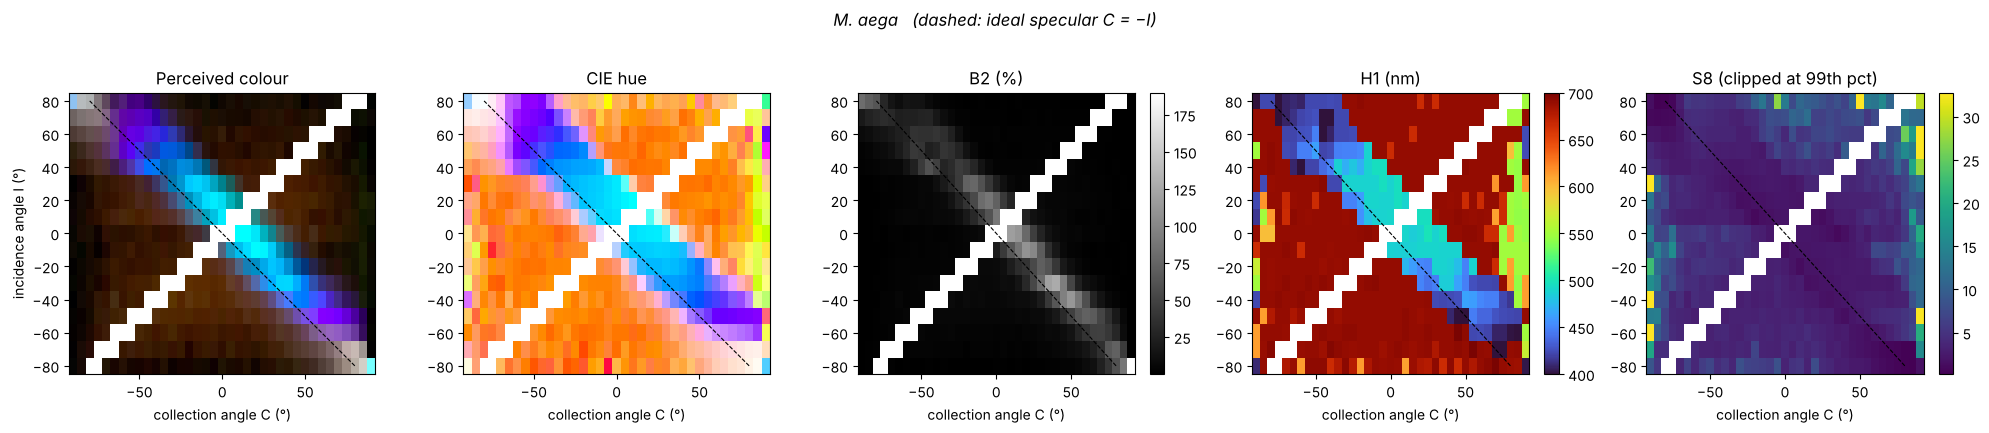

In [3]:
fig = atlas_panel("aega"); fig.savefig("../figures/atlas_aega_maps.png", dpi=150, bbox_inches="tight")

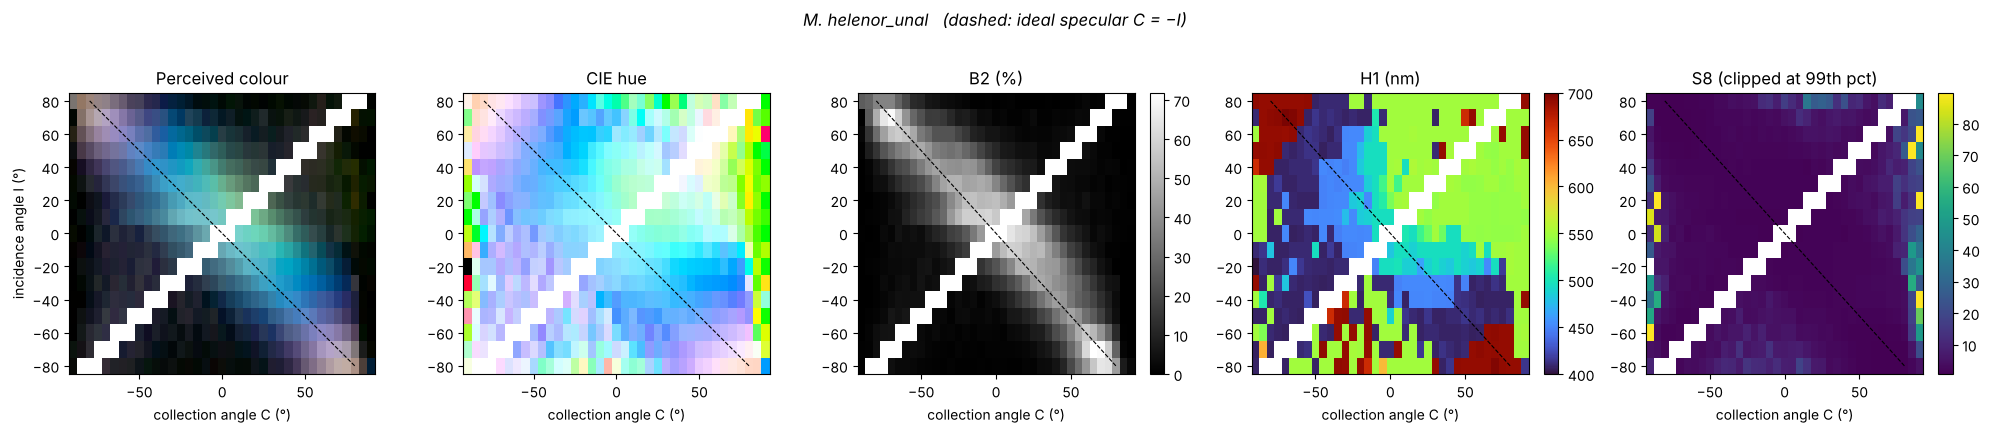

In [4]:
fig = atlas_panel("helenor_unal"); fig.savefig("../figures/atlas_helenor_unal_maps.png", dpi=150, bbox_inches="tight")

Any species can be drawn with `atlas_panel("<species_id>")`. The interactive version, with the raw and cleaned spectrum of every cell and the Gruson fits overlaid, is `atlas/viewer/Morpho_Angular_Atlas_offline.html` (double-click to open).